<a href="https://colab.research.google.com/github/Franncippi/Proyecto-mentoria-M09/blob/main/Proyecto-mentoria-M09/blob/main/notebooks/03_modelado_final.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctico 3 — Modelado

**Mentoría M09 — El impacto de la IA en la fuerza laboral**

Dataset: [diplodatos-ai-impact-workforce](https://github.com/carolinapepe/diplodatos-ai-impact-workforce) (curado en el P2: `empresas.parquet`, 10.000 empresas)

---

## Qué hace esta notebook

Retoma la **Hipótesis 2** del P1 — *¿se puede predecir el saldo neto de empleo de una empresa a partir de su adopción de IA y sus características?* — con un enfoque mixto en dos partes que se leen en orden:

| Parte | Técnica | Pregunta que responde | Rol en la conclusión |
|---|---|---|---|
| **A** | No supervisado (PCA + clustering) | ¿Cómo está estructurada la adopción de IA? ¿Hay *tipos* de empresa o un *gradiente*? | Da el **contexto**: qué esperar y qué no |
| **B** | Supervisado (regresión logística **penalizada**: Ridge / Lasso / Elastic Net) | ¿Se puede predecir si el saldo neto es positivo? ¿Con qué variables? | Da la **respuesta predictiva** |
| **C** | Integración | ¿Qué agrega A a la lectura de B? | Vuelta al P1 y conclusiones (puntos 5 y 6 de la consigna) |

**Correspondencia con la consigna del P3:** punto 1 → Parte 0 · punto 2 (preparación) → A.1 y B.1–B.2 · punto 3 (implementación y evaluación) → A.2–A.4 y B.3–B.6 · punto 4 (interpretación) → A.5 y B.7 · puntos 5 y 6 → Parte C.

## Decisiones clave (para leer antes que el código)

1. **Target:** `saldo_neto_positivo = 1` si `saldo_neto_empleo > 0`. Es la lectura más literal de la H2. Se documenta que `saldo_neto_empleo` es una variable ruidosa (fiabilidad 0,33 según el P2, §10.6.2).
2. **Variables de país fuera de los dos enfoques.** Los 5 indicadores de contexto-país toman solo 30 valores distintos para 10.000 empresas (son una constante por país): no describen diferencias *entre empresas* y, en el no supervisado, generan bandas artificiales en la proyección. Se verifica en B.6 que incluirlas no cambia el resultado.
3. **Regresión penalizada, no solo logística plana.** Hay 34 columnas de entrada (con los dummies), varias fuertemente correlacionadas (`ai_adoption_rate` ↔ `task_automation_rate`: r ≈ 0,91). La penalización estabiliza los coeficientes y, con L1, hace selección de variables. **Se muestra honestamente que no mejora el AUC** respecto de la logística sin penalizar: su aporte es parsimonia e interpretabilidad.
4. **El no supervisado nunca ve el resultado.** El clustering y el PCA se arman solo con predictores; los resultados se miran *después* para describir (si no, es circular).
5. **Escalado dentro de un `Pipeline`** en el supervisado, para que el ajuste ocurra solo con el train de cada fold (sin fuga de información).

---
# Parte 0 — Enfoque elegido y datos

## 0.1 La pregunta (P1 → H2)

La H2 del P1 preguntaba si el saldo neto de empleo (creado − desplazado) puede predecirse a partir de la adopción de IA y las características de la empresa. En el P1 se observó, a nivel industria, que Technology crea y desplaza más empleo que el resto, y que industrias con automatización similar tienen saldos opuestos: la automatización *habilita* pero no *determina* el desplazamiento. En el P2 se descartó `ai_use_case` como predictor central (está determinada por la industria) y se armó un catálogo de predictores por rol (estructura, adopción, operación, gobernanza, país).

## 0.2 Por qué un enfoque mixto

Hay dos lecturas legítimas de la H2 y cada una pide una técnica distinta:

- **¿Se puede predecir?** → problema supervisado (clasificación). Responde con una métrica cuantificable (AUC, accuracy) y con coeficientes interpretables.
- **¿Cómo se organiza la adopción de IA entre las empresas?** → problema no supervisado. No predice nada: describe la estructura de los predictores sin mirar el resultado.

El no supervisado *no es un paso previo obligatorio* del supervisado, pero aporta algo que el modelo predictivo no puede darse a sí mismo: **saber qué tipo de señal hay en los datos**. Si hubiera tipos discretos de empresa, tendría sentido modelar por perfil o agregar el perfil como variable; si lo que hay es un gradiente continuo, un modelo lineal sobre las variables originales es la herramienta natural. Esa es la conexión que se retoma en la Parte C.

## 0.3 Carga de datos y catálogo de predictores

In [ ]:
import subprocess, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from scipy import stats

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.metrics import (silhouette_score, roc_auc_score, accuracy_score, balanced_accuracy_score,
                             f1_score, ConfusionMatrixDisplay, RocCurveDisplay)

warnings.filterwarnings("ignore")
SEMILLA = 42
np.random.seed(SEMILLA)
sns.set_theme(style="whitegrid", context="notebook")

# Carga: ruta local si la notebook corre dentro del repo; si no (Colab), se clona el repo.
RUTAS = [Path("../data/processed/empresas.parquet"),
         Path("data/processed/empresas.parquet"),
         Path("repo_m09/data/processed/empresas.parquet")]
ruta_datos = next((r for r in RUTAS if r.exists()), None)
if ruta_datos is None:
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/Franncippi/Proyecto-mentoria-M09.git", "repo_m09"], check=True)
    ruta_datos = RUTAS[-1]

empresas = pd.read_parquet(ruta_datos)
print(empresas.shape, "| nulos:", int(empresas.isna().sum().sum()))

(10000, 65) | nulos: 0


In [ ]:
# Catálogo de predictores por rol (P2, §11.2). Las variables de rol "resultado" nunca entran como predictores.
PRED_ESTRUCTURA = ["num_employees", "annual_revenue_usd_millions", "company_age"]
PRED_ADOPCION   = ["ai_adoption_rate", "years_using_ai", "num_ai_tools_used", "ai_projects_active",
                   "ai_budget_percentage", "ai_training_hours", "antiguedad_ia_relativa"]
PRED_OPERACION  = ["task_automation_rate", "remote_work_percentage"]
PRED_GOBERNANZA = ["ai_failure_rate", "regulatory_compliance_score", "ai_risk_management_score"]
PRED_PAIS       = ["gdp_per_capita", "internet_penetration", "digital_maturity_index",
                   "ai_patent_filings_2024", "ai_researchers_per_million"]
PRED_CATEG      = ["industry", "region", "ai_adoption_stage", "country_ai_policy", "ai_ethics_committee"]

PRED_NUM = PRED_ESTRUCTURA + PRED_ADOPCION + PRED_OPERACION + PRED_GOBERNANZA + PRED_PAIS

# ¿Por qué se excluye PRED_PAIS? Son constantes por país, no por empresa:
print("países distintos:", empresas["country"].nunique())
print(empresas[PRED_PAIS].nunique().to_frame("valores distintos (sobre 10.000 filas)").T)

países distintos: 30
                                        gdp_per_capita  internet_penetration  \
valores distintos (sobre 10.000 filas)              30                    30   

                                        digital_maturity_index  \
valores distintos (sobre 10.000 filas)                      30   

                                        ai_patent_filings_2024  \
valores distintos (sobre 10.000 filas)                      30   

                                        ai_researchers_per_million  
valores distintos (sobre 10.000 filas)                          30  


---
# Parte A — Aprendizaje no supervisado: la estructura de la adopción de IA

> **Regla de separación (P2, §11.2):** si se clusteriza incluyendo variables de resultado, los grupos se separan por resultado y después "descubrir" que el grupo que más adoptó IA es el que mejor le fue es circular. Acá se trabaja **solo con predictores**; los resultados aparecen únicamente en A.5, para describir.

## A.1 Preparación

**Variables (15):** estructura + adopción + operación + gobernanza. Quedan afuera:
- *Variables de país*, por lo ya visto (30 valores para 10.000 filas). Incluidas, generan bandas discretas en PC2 que son un artefacto de medir a nivel país y no a nivel empresa.
- *Categóricas*: la distancia euclídea (K-means) y la covarianza (PCA) no tienen sentido sobre etiquetas. Se usan después para describir.
- *Resultados*: ver la regla de separación.

**Transformación logarítmica de tamaño.** `num_employees` y `annual_revenue_usd_millions` son muy asimétricas (cola larga a la derecha). PCA trabaja sobre varianzas: una variable con unos pocos valores extremos domina la varianza y puede producir un "eje de tamaño" artificial. `log1p` comprime la cola.

**Estandarizado (obligatorio).** PCA y K-means usan distancias/varianzas: sin estandarizar, la variable con mayor escala (p. ej. `num_employees`) dominaría sin relación con cuánta información aporta. Estandarizar equivale a hacer PCA sobre la **matriz de correlaciones**.

In [ ]:
VARS_NO_SUP = PRED_ESTRUCTURA + PRED_ADOPCION + PRED_OPERACION + PRED_GOBERNANZA
VARS_LOG = ["num_employees", "annual_revenue_usd_millions"]

X_ns = empresas[VARS_NO_SUP].copy()
asimetria = pd.DataFrame({"antes": X_ns[VARS_LOG].skew()})
X_ns[VARS_LOG] = np.log1p(X_ns[VARS_LOG])
asimetria["después (log1p)"] = X_ns[VARS_LOG].skew()
print(asimetria.round(2))

X_scaled = StandardScaler().fit_transform(X_ns)
print(f"\n{X_scaled.shape[1]} variables estandarizadas: media ≈ {X_scaled.mean():.2f}, desvío ≈ {X_scaled.std():.2f}")

                             antes  después (log1p)
num_employees                 2.28             0.47
annual_revenue_usd_millions   2.28             0.33

15 variables estandarizadas: media ≈ 0.00, desvío ≈ 1.00


## A.2 PCA: reducción de dimensionalidad

**Por qué PCA antes de agrupar.** Varias variables de adopción están muy correlacionadas entre sí (se ve abajo: r hasta ≈ 0,94). Sin corregirlo, esa dimensión conceptual pesaría varias veces en la distancia euclídea. PCA reemplaza las variables originales por combinaciones lineales **ortogonales** ordenadas por varianza explicada.

**Cuántos componentes.** Se comparan dos criterios estándar: el de **Kaiser** (retener componentes con autovalor > 1, es decir, que expliquen más que una variable original estandarizada) y el de **varianza acumulada ≥ 80 %**. En A.3 se verifica que la conclusión no depende de esta elección.

Correlaciones más altas entre variables (|r| > 0.8):
ai_training_hours     ai_failure_rate                0.94
ai_adoption_rate      ai_training_hours              0.94
                      ai_failure_rate                0.92
company_age           antiguedad_ia_relativa         0.92
ai_adoption_rate      task_automation_rate           0.91
                      ai_budget_percentage           0.90
num_employees         annual_revenue_usd_millions    0.90
ai_budget_percentage  ai_training_hours              0.89
ai_adoption_rate      num_ai_tools_used              0.87
ai_budget_percentage  ai_failure_rate                0.87
ai_projects_active    ai_training_hours              0.86
                      ai_budget_percentage           0.86
ai_training_hours     task_automation_rate           0.85
ai_adoption_rate      ai_projects_active             0.85
ai_projects_active    ai_failure_rate                0.84
task_automation_rate  ai_failure_rate                0.84
num_ai_tools_used  

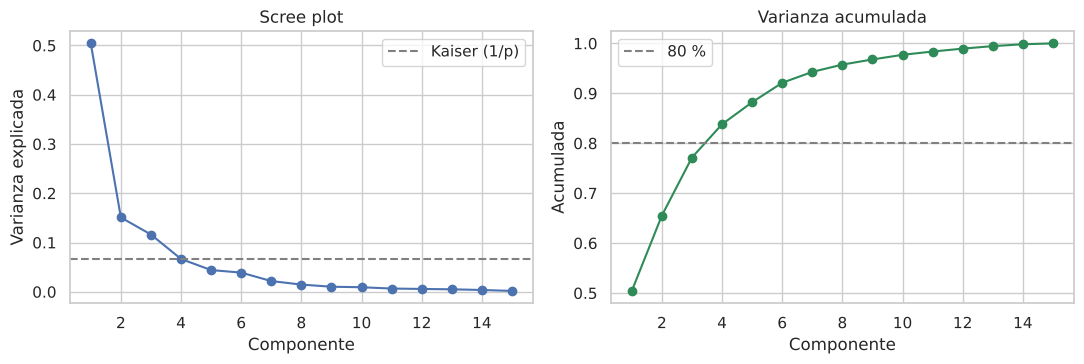

PC1 explica 50.4%. Kaiser retiene 3 componentes; 80 % requiere 4.


In [ ]:
print("Correlaciones más altas entre variables (|r| > 0.8):")
corr = X_ns.corr().abs().where(np.triu(np.ones((15, 15), bool), 1)).stack()
print(corr[corr > 0.8].sort_values(ascending=False).round(2).to_string())

pca_full = PCA(random_state=SEMILLA).fit(X_scaled)
var_exp = pca_full.explained_variance_ratio_
cum_var = np.cumsum(var_exp)
n_kaiser = int((pca_full.explained_variance_ > 1).sum())
n80 = int(np.argmax(cum_var >= 0.80) + 1)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(range(1, 16), var_exp, "o-")
axes[0].axhline(1/15, color="gray", ls="--", label="Kaiser (1/p)")
axes[0].set(title="Scree plot", xlabel="Componente", ylabel="Varianza explicada"); axes[0].legend()
axes[1].plot(range(1, 16), cum_var, "o-", color="seagreen")
axes[1].axhline(0.8, color="gray", ls="--", label="80 %")
axes[1].set(title="Varianza acumulada", xlabel="Componente", ylabel="Acumulada"); axes[1].legend()
plt.tight_layout(); plt.show()
print(f"PC1 explica {var_exp[0]:.1%}. Kaiser retiene {n_kaiser} componentes; 80 % requiere {n80}.")

Varianza retenida con 4 componentes: 83.8%


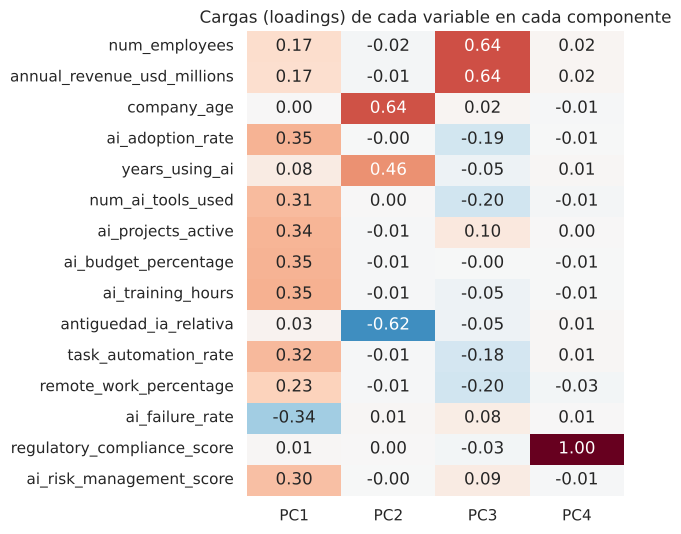

In [ ]:
N_COMP = n80   # criterio del 80 % (Kaiser da uno menos y queda justo en el borde)
pca = PCA(n_components=N_COMP, random_state=SEMILLA)
X_pca = pca.fit_transform(X_scaled)

# El signo de un componente es arbitrario: se fija para que PC1 crezca con ai_adoption_rate.
signo = np.sign(pca.components_[0, VARS_NO_SUP.index("ai_adoption_rate")])
X_pca[:, 0] *= signo
pca.components_[0] *= signo
empresas["PC1"] = X_pca[:, 0]

cargas = pd.DataFrame(pca.components_.T, index=VARS_NO_SUP, columns=[f"PC{i+1}" for i in range(N_COMP)])
print(f"Varianza retenida con {N_COMP} componentes: {pca.explained_variance_ratio_.sum():.1%}")
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(cargas, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar=False)
plt.title("Cargas (loadings) de cada variable en cada componente"); plt.tight_layout(); plt.show()

**Lectura de los componentes** (qué variables pesan en cada uno):

- **PC1 — intensidad de adopción de IA** (≈ 50 % de la varianza). Pesa parecido y con el mismo signo en `ai_adoption_rate`, `ai_training_hours`, `ai_budget_percentage`, `ai_projects_active`, `num_ai_tools_used`, `task_automation_rate` y `ai_risk_management_score`, y con signo contrario en `ai_failure_rate`. Es un eje único de "cuánto y cuán maduramente adoptó IA la empresa".
- **PC2 — trayectoria temporal:** `company_age` y `years_using_ai` contra `antiguedad_ia_relativa` (cuánto tiempo lleva la empresa y usando IA vs. qué fracción de su vida usa IA).
- **PC3 — tamaño** (`num_employees` y `annual_revenue_usd_millions` juntas).
- **PC4 — `regulatory_compliance_score`**, casi sola: es una variable que no se parece a ninguna otra y PCA no puede comprimirla.

Que casi toda la varianza compartida caiga en *un* componente es ya una pista sobre lo que viene: no hay muchas dimensiones independientes de adopción, hay una.

## A.3 ¿Hay grupos? K-means, un control gaussiano y DBSCAN

**Silhouette (Rousseeuw, 1987).** Para cada punto compara su distancia media a su propio grupo con la distancia media al grupo más cercano; va de −1 a 1. Convención de Kaufman y Rousseeuw (1990): **> 0,70** estructura fuerte; **0,51–0,70** razonable; **0,26–0,50** débil, *posiblemente artificial*; **< 0,25** sin estructura sustancial.

**El problema de interpretar un silhouette solo.** K-means siempre entrega una partición, aunque los datos sean una sola nube continua. Un silhouette de ~0,3 podría ser "estructura débil" o simplemente "lo que K-means obtiene al cortar una nube gaussiana". Para distinguirlo se usa un **control**: se simulan datos gaussianos con *la misma covarianza* que los componentes observados (una sola nube por construcción) y se calcula el silhouette con el mismo procedimiento. Si lo observado no supera al control, no hay evidencia de grupos.

Además se mira (a) el histograma de PC1 —si hubiera grupos separados, sería bimodal— y (b) **DBSCAN** (Ester et al., 1996), que no impone un número de grupos: encuentra regiones densas y marca como ruido lo que queda en el medio.

In [ ]:
# Sensibilidad a la cantidad de componentes: ¿cambia el silhouette de K-means?
filas = []
for nc in (3, 4, 5):
    Z = PCA(n_components=nc, random_state=SEMILLA).fit_transform(X_scaled)
    for k in (2, 3, 4):
        lab = KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(Z)
        filas.append({"componentes": nc, "k": k, "silhouette": silhouette_score(Z, lab)})
print(pd.DataFrame(filas).pivot(index="componentes", columns="k", values="silhouette").round(3))

k                2      3      4
componentes                     
3            0.354  0.265  0.288
4            0.323  0.231  0.247
5            0.306  0.214  0.227


 k  observado  control gaussiano
 2      0.323              0.305
 3      0.231              0.224
 4      0.247              0.217
 5      0.223              0.189
 6      0.233              0.184



DBSCAN (eps=1.10, min_samples=20): tamaños de grupo (-1 = ruido):
 0    9759
-1     241


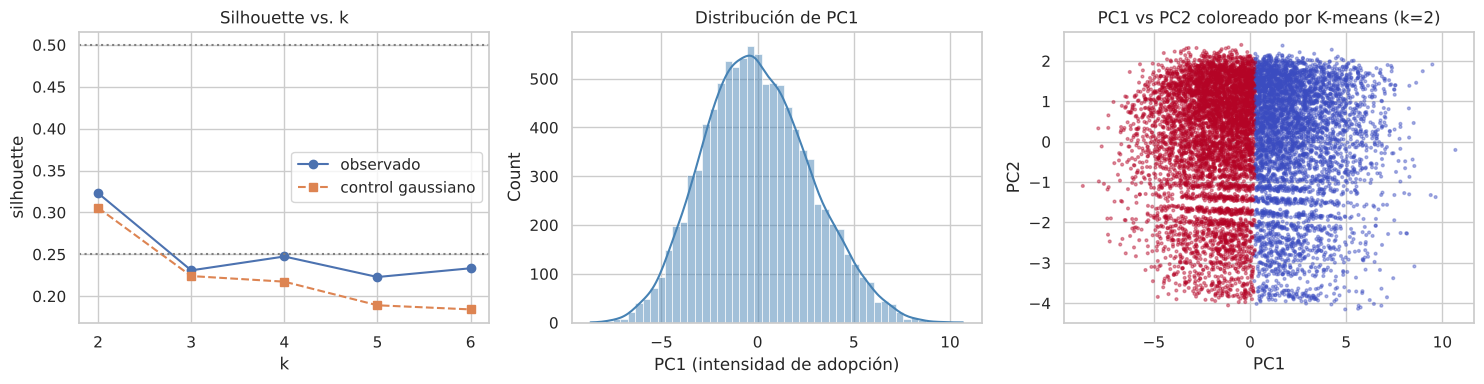

PC1: asimetría = 0.22, curtosis en exceso = -0.20


In [ ]:
# Silhouette observado vs. control gaussiano (misma covarianza, una sola nube)
rng = np.random.default_rng(SEMILLA)
G = rng.multivariate_normal(np.zeros(N_COMP), np.cov(X_pca.T), size=len(X_pca))

ks = range(2, 7)
sil_obs = [silhouette_score(X_pca, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(X_pca)) for k in ks]
sil_gauss = [silhouette_score(G, KMeans(k, n_init=10, random_state=SEMILLA).fit_predict(G)) for k in ks]
print(pd.DataFrame({"k": list(ks), "observado": sil_obs, "control gaussiano": sil_gauss}).round(3).to_string(index=False))

# DBSCAN: eps tomado del percentil 90 de la distancia al vecino número MIN_PTS
MIN_PTS = 20
dist_knn, _ = NearestNeighbors(n_neighbors=MIN_PTS).fit(X_pca).kneighbors(X_pca)
eps = np.percentile(dist_knn[:, -1], 90)
lab_db = DBSCAN(eps=eps, min_samples=MIN_PTS).fit_predict(X_pca)
tam_db = pd.Series(lab_db).value_counts()
print(f"\nDBSCAN (eps={eps:.2f}, min_samples={MIN_PTS}): tamaños de grupo (-1 = ruido):")
print(tam_db.to_string())

# Corte de K-means con k=2 (solo para visualizar qué hace sobre una nube continua)
empresas["cluster_k2"] = KMeans(2, n_init=10, random_state=SEMILLA).fit_predict(X_pca)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(list(ks), sil_obs, "o-", label="observado")
axes[0].plot(list(ks), sil_gauss, "s--", label="control gaussiano")
axes[0].axhline(0.5, color="gray", ls=":"); axes[0].axhline(0.25, color="gray", ls=":")
axes[0].set(title="Silhouette vs. k", xlabel="k", ylabel="silhouette"); axes[0].legend()
sns.histplot(X_pca[:, 0], bins=50, kde=True, ax=axes[1], color="steelblue")
axes[1].set(title="Distribución de PC1", xlabel="PC1 (intensidad de adopción)")
axes[2].scatter(X_pca[:, 0], X_pca[:, 1], c=empresas["cluster_k2"], cmap="coolwarm", s=4, alpha=0.4)
axes[2].set(title="PC1 vs PC2 coloreado por K-means (k=2)", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()
print(f"PC1: asimetría = {stats.skew(X_pca[:, 0]):.2f}, curtosis en exceso = {stats.kurtosis(X_pca[:, 0]):.2f}")

**Lectura.**
- El silhouette observado es débil (≈ 0,32 con k=2; entre 0,31 y 0,35 según la cantidad de componentes: siempre en la zona "posiblemente artificial") y queda **apenas por encima del control gaussiano** (0,31 con k=2; diferencias de 0,02 a 0,05 para el resto de los k): K-means no encuentra prácticamente nada que no encontraría en una única nube continua.
- PC1 tiene una distribución unimodal y casi simétrica: no hay dos "joroba".
- DBSCAN devuelve **un solo grupo** con el 97,6 % de las empresas y marca como ruido al 2,4 % restante; no separa nada.
- En el gráfico de la derecha, el corte de K-means cae alrededor de PC1 ≈ 0 y parte la nube por la mitad: **los colores no son grupos reales, son una partición arbitraria de un continuo** (las franjas horizontales en PC2 tampoco son grupos: `company_age` toma apenas 33 valores enteros). Por eso de acá en adelante se trabaja con la coordenada continua `PC1`, no con la etiqueta del cluster.

**Conclusión de A.3:** no hay tipos discretos de empresa. Lo que hay es un **gradiente continuo de intensidad de adopción**.

## A.4 Validación externa del eje PC1

¿PC1 mide realmente adopción de IA? `ai_adoption_stage` (none < pilot < partial < full) es una variable categórica que **no entró** al PCA. Si PC1 es de verdad intensidad de adopción, debería crecer de forma monótona con la etapa (*validez convergente*).

                   count  mean   std
ai_adoption_stage                   
none                  77 -6.34  0.82
pilot               4320 -2.23  1.51
partial             5594  1.80  2.00
full                   9  8.44  1.55


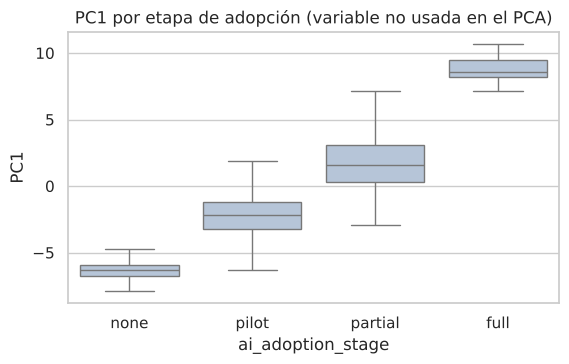

In [ ]:
orden = ["none", "pilot", "partial", "full"]
validacion = (empresas.groupby("ai_adoption_stage")["PC1"].agg(["count", "mean", "std"])
              .reindex(orden).round(2))
print(validacion)

plt.figure(figsize=(6, 3.8))
sns.boxplot(data=empresas, x="ai_adoption_stage", y="PC1", order=orden, color="lightsteelblue", showfliers=False)
plt.title("PC1 por etapa de adopción (variable no usada en el PCA)"); plt.tight_layout(); plt.show()

PC1 crece de forma monótona con la etapa de adopción. Cautela de lectura: las etapas `none` (77 empresas) y `full` (9) son muy poco frecuentes; el grueso está en `pilot` y `partial`, así que la validación es sólida en el centro de la distribución y anecdótica en los extremos.

## A.5 Interpretación: ¿qué tiene que ver el gradiente con el empleo? (recién ahora se miran los resultados)

Se describe la relación entre PC1 y los resultados de empleo, sin que éstos hayan intervenido en su construcción. Se divide la muestra en terciles de PC1 y se calcula el **tamaño del efecto** (d de Cohen) entre el tercil alto y el bajo: diferencia de medias en unidades de desvío estándar combinado (≈ 0,2 chico, 0,5 mediano, 0,8 grande, según la convención de Cohen).

In [ ]:
empresas["tercil_PC1"] = pd.qcut(empresas["PC1"], 3, labels=["bajo", "medio", "alto"])
empresas["_saldo_pos"] = (empresas["saldo_neto_empleo"] > 0).astype(int)

tabla_terciles = empresas.groupby("tercil_PC1", observed=True).agg(
    n=("PC1", "size"),
    tasa_creacion=("tasa_creacion", "mean"),
    tasa_desplazamiento=("tasa_desplazamiento", "mean"),
    saldo_neto=("saldo_neto_empleo", "mean"),
    pct_saldo_positivo=("_saldo_pos", "mean")).round(3)
print(tabla_terciles)

def d_cohen(a, b):
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

alto = empresas.loc[empresas.tercil_PC1 == "alto", "saldo_neto_empleo"]
bajo = empresas.loc[empresas.tercil_PC1 == "bajo", "saldo_neto_empleo"]
print(f"\nd de Cohen del saldo neto (tercil alto vs bajo de PC1): {d_cohen(alto, bajo):.2f}")
print(empresas[["PC1", "tasa_creacion", "tasa_desplazamiento", "saldo_neto_empleo"]].corr().loc["PC1"].round(3).to_string())

# ¿El efecto es homogéneo entre industrias? (si no lo fuera, la industria confundiría la lectura)
por_industria = empresas.groupby("industry").apply(lambda d: d["PC1"].corr(d["saldo_neto_empleo"]))
print(f"\ncorrelación PC1–saldo neto por industria: mín {por_industria.min():.2f}, máx {por_industria.max():.2f}")

               n  tasa_creacion  tasa_desplazamiento  saldo_neto  \
tercil_PC1                                                         
bajo        3334          3.071                3.226      -0.155   
medio       3333          4.355                4.271       0.084   
alto        3333          5.671                5.305       0.365   

            pct_saldo_positivo  
tercil_PC1                      
bajo                     0.382  
medio                    0.546  
alto                     0.722  

d de Cohen del saldo neto (tercil alto vs bajo de PC1): 0.85
PC1                    1.000
tasa_creacion          0.932
tasa_desplazamiento    0.839
saldo_neto_empleo      0.372

correlación PC1–saldo neto por industria: mín 0.32, máx 0.39


**Hallazgos de la Parte A.**

1. **No hay tipos de empresa; hay un gradiente.** El silhouette de K-means es débil y casi igual al de una nube gaussiana, PC1 es unimodal y DBSCAN encuentra un único grupo.
2. **El gradiente es una dimensión coherente de adopción de IA** (≈ 50 % de la varianza de los predictores; creciente con `ai_adoption_stage`).
3. **Asociado al empleo, pero de una forma matizada:** al subir PC1 **suben a la vez** la creación y el desplazamiento de empleo (r ≈ 0,93 y 0,84), y el saldo neto sube solo moderadamente (r ≈ 0,37; d ≈ 0,85 entre terciles extremos). El saldo es la *diferencia de dos magnitudes grandes y correlacionadas*.
4. **El efecto es parejo entre industrias** (r entre 0,32 y 0,39), así que la industria no parece estar confundiendo.

**Lo que el no supervisado *no* puede decir:** si PC1 alcanza para *predecir* el signo del saldo de una empresa concreta, y qué aspecto de la adopción es el relevante. Eso es lo que sigue.

---
# Parte B — Aprendizaje supervisado: regresión logística penalizada

## B.1 Definición del target y de los predictores

`saldo_neto_positivo = 1` si `saldo_neto_empleo > 0`, `0` si no. Los 386 casos con saldo exactamente 0 se asignan a la clase 0: la pregunta es "¿hubo ganancia neta de empleo?" y un saldo nulo no lo es. A diferencia de un corte por mediana, **el balance de clases no está garantizado por construcción**: se verifica.

**Predictores (20 columnas originales → 34 tras el one-hot):** estructura, adopción, operación, gobernanza (15 numéricas) y 5 categóricas (`industry`, `region`, `ai_adoption_stage`, `country_ai_policy`, `ai_ethics_committee`). Se excluyen las variables de rol *resultado* (serían circulares) y las de país (A.1; se comprueba en B.6 que dejarlas no cambia nada).

In [ ]:
empresas["saldo_neto_positivo"] = (empresas["saldo_neto_empleo"] > 0).astype(int)
print("saldo exactamente 0:", int((empresas.saldo_neto_empleo == 0).sum()))
print("balance de clases:\n", empresas["saldo_neto_positivo"].value_counts(normalize=True).round(3).to_string())

PRED_SUP = PRED_ESTRUCTURA + PRED_ADOPCION + PRED_OPERACION + PRED_GOBERNANZA + PRED_CATEG
PRED_SUP_CON_PAIS = PRED_SUP + PRED_PAIS
y = empresas["saldo_neto_positivo"]

saldo exactamente 0: 386
balance de clases:
 saldo_neto_positivo
1    0.55
0    0.45


Hay 55 % de saldos positivos y 45 % no positivos: un desbalance leve (ratio ≈ 1,2), que no justifica remuestreo. Una regla trivial que prediga siempre "positivo" acertaría ≈ 55 %: ese es el **piso** contra el cual medir la accuracy. Como métrica principal se usa el **ROC-AUC** (probabilidad de que el modelo asigne mayor puntaje a un positivo que a un negativo elegidos al azar; no depende del umbral y es robusta al leve desbalance), y se informan también accuracy, balanced accuracy y F1.

## B.2 Split, validación cruzada y preprocesamiento

- **Split 80/20 estratificado.** El 20 % de *test* se reserva y se usa **una sola vez**, para la evaluación final. No interviene en ninguna elección.
- **StratifiedKFold (5 folds) sobre el train** para comparar modelos y elegir el hiperparámetro de penalización. Validación cruzada = estimar el error de generalización reutilizando los datos: cada observación se usa 4 veces para entrenar y 1 para validar.
- **Unidad de análisis:** una fila por empresa (no el panel trimestral), lo que evita fuga por `company_id` repetido entre train y test.
- **Escalado + one-hot dentro de un `Pipeline`.** Si se estandarizara antes del split, la media y el desvío del test "filtrarían" al entrenamiento. En un pipeline, `fit` ocurre solo con el train de cada fold. El escalado además es **imprescindible con penalización**: la penalidad suma |coeficientes| o sus cuadrados, así que depende de la escala de cada variable; sin estandarizar, la penalización castigaría más a las variables medidas en unidades "chicas".

In [ ]:
train_idx, test_idx = train_test_split(empresas.index, test_size=0.2, random_state=SEMILLA, stratify=y)
y_train, y_test = y.loc[train_idx], y.loc[test_idx]
print(f"train: {len(train_idx)}  test: {len(test_idx)}  | % positivos train/test: {y_train.mean():.3f} / {y_test.mean():.3f}")

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def preprocesador(predictores):
    num = [c for c in predictores if c in PRED_NUM]
    cat = [c for c in predictores if c in PRED_CATEG]
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat)])

def armar_pipeline(predictores, clf):
    return Pipeline([("prep", preprocesador(predictores)), ("clf", clf)])

# scikit-learn >= 1.8 define la penalización con C + l1_ratio (el argumento `penalty` quedó deprecado);
# en versiones anteriores se usa `penalty`. Esta función funciona con ambas.
SK_NUEVO = tuple(int(v) for v in sklearn.__version__.split(".")[:2]) >= (1, 8)

def regresion_logistica(penalizacion, C=1.0, l1_ratio=0.5):
    """penalizacion: 'ninguna' | 'l2' (Ridge) | 'l1' (Lasso) | 'elasticnet'. C = 1/lambda (C chico = penaliza fuerte)."""
    base = dict(max_iter=10000, random_state=SEMILLA)
    solver = "lbfgs" if penalizacion in ("ninguna", "l2") else "saga"
    if SK_NUEVO:
        if penalizacion == "ninguna":
            return LogisticRegression(C=np.inf, l1_ratio=0, **base)
        l1 = {"l2": 0.0, "l1": 1.0, "elasticnet": l1_ratio}[penalizacion]
        return LogisticRegression(C=C, l1_ratio=l1, solver=solver, **base)
    if penalizacion == "ninguna":
        return LogisticRegression(penalty=None, **base)
    extra = {"l1_ratio": l1_ratio} if penalizacion == "elasticnet" else {}
    return LogisticRegression(penalty=penalizacion, C=C, solver=solver, **extra, **base)

print("scikit-learn", sklearn.__version__, "| API nueva:", SK_NUEVO)

train: 8000  test: 2000  | % positivos train/test: 0.550 / 0.550
scikit-learn 1.9.1 | API nueva: True


## B.3 Fundamento teórico: regresión logística con penalización

**Regresión logística.** Modela la log-odds del evento como combinación lineal de los predictores, $\log\frac{p}{1-p}=\beta_0+\sum_j\beta_j x_j$, y estima los $\beta$ minimizando la pérdida logarítmica (equivale a máxima verosimilitud). Cada $\beta_j$ (con $x_j$ estandarizada) es el cambio en log-odds por cada desvío estándar de $x_j$, **manteniendo el resto fijo**; $e^{\beta_j}$ es el *odds ratio*.

**Penalización (regularización).** Se agrega un costo por la magnitud de los coeficientes:

$$\min_{\beta}\;\; \underbrace{\sum_i \text{pérdida logística}_i}_{\text{ajuste a los datos}} \;+\; \lambda\, P(\beta)$$

| Modelo | Penalidad $P(\beta)$ | Efecto sobre los coeficientes |
|---|---|---|
| **Ridge (L2)** | $\tfrac12\sum_j\beta_j^2$ | Los encoge hacia 0 pero **nunca los anula**; reparte el peso entre variables correlacionadas |
| **Lasso (L1)** | $\sum_j\lvert\beta_j\rvert$ | Encoge y **anula** coeficientes: selecciona variables. Entre predictores muy correlacionados tiende a quedarse con uno (arbitrariamente) |
| **Elastic Net** | $\alpha\sum\lvert\beta_j\rvert+(1-\alpha)\tfrac12\sum\beta_j^2$ | Compromiso (Zou y Hastie, 2005): selecciona, pero tiende a retener grupos de variables correlacionadas |

En scikit-learn el parámetro es $C\approx 1/\lambda$: **C chico = penalización fuerte**.

**Por qué penalizar.** Es el compromiso *sesgo–varianza*: encoger los coeficientes introduce un poco de sesgo y a cambio baja la varianza de la estimación, lo que ayuda cuando hay muchas variables, poco dato o predictores correlacionados (la varianza de los coeficientes de OLS/logística se infla con la colinealidad). **Por qué L1 anula coeficientes:** la restricción $\sum|\beta_j|\le t$ tiene forma de rombo con vértices sobre los ejes, y el óptimo suele caer en un vértice, donde algunos $\beta_j=0$; con L2 la restricción es una esfera, sin vértices.

**Expectativa honesta para este problema.** Con ≈ 8.000 filas de entrenamiento y 34 columnas, la relación datos/parámetros es alta, así que el sobreajuste de la logística plana es chico. Es esperable que la penalización **casi no mejore el AUC**; su valor está en (i) estabilizar la lectura de los coeficientes frente a la colinealidad y (ii) con L1, *decir qué variables sobreviven*, que es justamente lo que pregunta la H2.

**Cómo se elige $C$.** Por validación cruzada sobre el train (nunca con el test). Para Lasso se aplica además la **regla de un error estándar** (Breiman et al., 1984; Hastie et al., 2009, §7.10): entre los valores de $C$ cuyo AUC de CV está a menos de 1 error estándar del mejor, se elige el **más penalizado** (el modelo más simple). Se prefiere el modelo más simple cuando la diferencia de desempeño está dentro del ruido de la estimación.

## B.4 Comparación de modelos (validación cruzada, solo sobre el train)

Se comparan: logística **sin** penalizar (línea base), Ridge, Lasso y Elastic Net, cada uno con su $C$ (y $\alpha$ en Elastic Net) tuneado por CV; y un Random Forest como referencia no lineal. Se reporta el AUC medio y su desvío entre folds: **diferencias menores al desvío no son diferencias reales**.

In [ ]:
GRILLA_C = np.logspace(-3, 1, 25)

candidatos = {
    "Logística sin penalizar": (regresion_logistica("ninguna"), {}),
    "Ridge (L2)":              (regresion_logistica("l2"), {"clf__C": GRILLA_C}),
    "Lasso (L1)":              (regresion_logistica("l1"), {"clf__C": GRILLA_C}),
    "Elastic Net":             (regresion_logistica("elasticnet"), {"clf__C": GRILLA_C[::2],
                                                                    "clf__l1_ratio": [0.2, 0.5, 0.8]}),
}

X_train = empresas.loc[train_idx, PRED_SUP]
grillas, filas = {}, []
for nombre, (clf, grilla) in candidatos.items():
    gs = GridSearchCV(armar_pipeline(PRED_SUP, clf), grilla or {"clf__max_iter": [10000]},
                      cv=cv, scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)
    grillas[nombre] = gs
    i = gs.best_index_
    filas.append({"modelo": nombre, "AUC CV (media)": gs.cv_results_["mean_test_score"][i],
                  "desvío entre folds": gs.cv_results_["std_test_score"][i],
                  "mejores hiperparámetros": {k.replace("clf__", ""): round(float(v), 4)
                                              for k, v in gs.best_params_.items() if k != "clf__max_iter"}})

rf = armar_pipeline(PRED_SUP, RandomForestClassifier(n_estimators=300, random_state=SEMILLA, n_jobs=-1))
sc_rf = cross_val_score(rf, X_train, y_train, cv=cv, scoring="roc_auc")
filas.append({"modelo": "Random Forest (referencia)", "AUC CV (media)": sc_rf.mean(),
              "desvío entre folds": sc_rf.std(), "mejores hiperparámetros": {}})

tabla_cv = pd.DataFrame(filas).sort_values("AUC CV (media)", ascending=False).reset_index(drop=True)
tabla_cv[["AUC CV (media)", "desvío entre folds"]] = tabla_cv[["AUC CV (media)", "desvío entre folds"]].round(4)
tabla_cv

,modelo,AUC CV (media),desvío entre folds,mejores hiperparámetros
0,Lasso (L1),0.8911,0.0020,{'C': 0.0464}
1,Elastic Net,0.8905,0.0018,"{'C': 0.1, 'l1_ratio': 0.8}"
2,Ridge (L2),0.8901,0.0020,{'C': 1.4678}
3,Logística sin penalizar,0.8900,0.0020,{}
4,Random Forest (referencia),0.8513,0.0056,{}


**Lectura.** Los cuatro modelos lineales empatan: sus AUC de CV difieren en la tercera cifra decimal, **por debajo del desvío entre folds**. Como se anticipó, la penalización no mejora la predicción; confirma que la logística plana no estaba sobreajustando. Random Forest queda **claramente por debajo**, lo que indica que la relación relevante es esencialmente lineal en los predictores estandarizados (un modelo más flexible agrega varianza sin capturar nada nuevo).

**Decisión:** se elige **Lasso (L1)**. No porque prediga mejor (no lo hace), sino porque a igual desempeño ofrece el modelo más parsimonioso y responde directamente a "¿qué variables importan?". Falta fijar $C$: se analiza la curva de CV y se aplica la regla de un error estándar.

## B.5 Elección de $C$ en Lasso: curva de validación y regla de 1 error estándar

C óptimo = 0.0464 (AUC CV 0.8911, error estándar 0.0009)
C por regla de 1 SE = 0.0215 (AUC CV 0.8908)


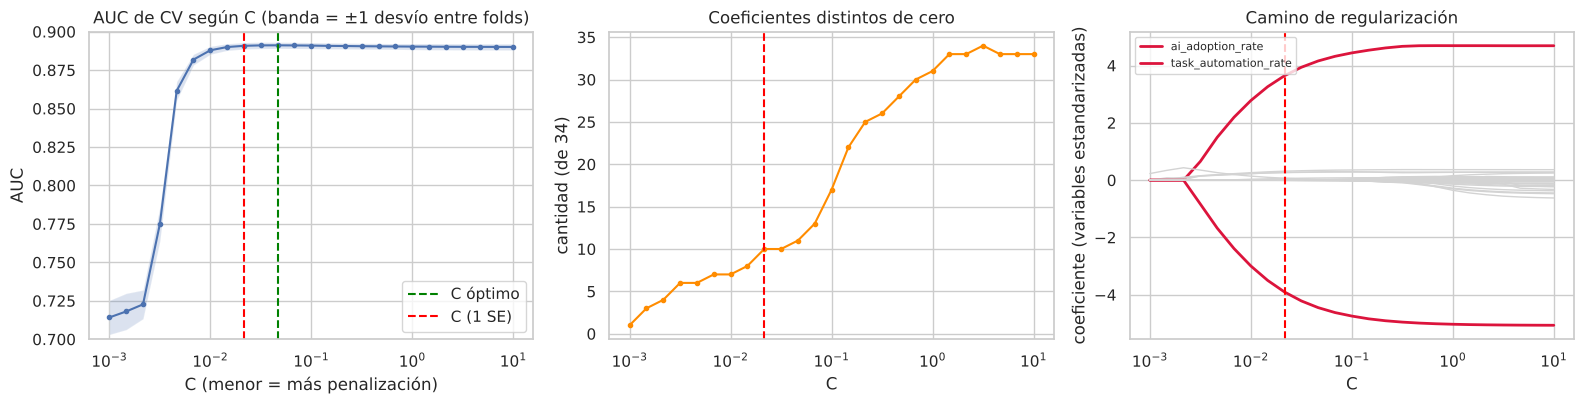

In [ ]:
gs_lasso = grillas["Lasso (L1)"]
medias = gs_lasso.cv_results_["mean_test_score"]
desvios = gs_lasso.cv_results_["std_test_score"]
Cs = np.array([p["clf__C"] for p in gs_lasso.cv_results_["params"]])

i_best = int(np.argmax(medias))
se_best = desvios[i_best] / np.sqrt(cv.get_n_splits())
umbral = medias[i_best] - se_best
C_1SE = Cs[medias >= umbral].min()          # el más penalizado que sigue dentro de 1 SE del mejor
print(f"C óptimo = {Cs[i_best]:.4f} (AUC CV {medias[i_best]:.4f}, error estándar {se_best:.4f})")
print(f"C por regla de 1 SE = {C_1SE:.4f} (AUC CV {medias[Cs == C_1SE][0]:.4f})")

# Coeficientes a lo largo de C (camino de regularización) y cantidad de coeficientes no nulos
camino, n_no_nulos = [], []
for c in Cs:
    p = armar_pipeline(PRED_SUP, regresion_logistica("l1", C=c)).fit(X_train, y_train)
    camino.append(p.named_steps["clf"].coef_[0]); n_no_nulos.append(int((p.named_steps["clf"].coef_[0] != 0).sum()))
nombres = armar_pipeline(PRED_SUP, regresion_logistica("l1")).fit(X_train, y_train).named_steps["prep"].get_feature_names_out()
camino = pd.DataFrame(camino, index=Cs, columns=[n.replace("num__", "").replace("cat__", "") for n in nombres])

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].plot(Cs, medias, "o-", ms=3); axes[0].fill_between(Cs, medias - desvios, medias + desvios, alpha=0.2)
axes[0].axvline(Cs[i_best], color="green", ls="--", label="C óptimo"); axes[0].axvline(C_1SE, color="red", ls="--", label="C (1 SE)")
axes[0].set_xscale("log"); axes[0].set_ylim(0.7, 0.9); axes[0].legend()
axes[0].set(title="AUC de CV según C (banda = ±1 desvío entre folds)", xlabel="C (menor = más penalización)", ylabel="AUC")
axes[1].plot(Cs, n_no_nulos, "o-", ms=3, color="darkorange"); axes[1].axvline(C_1SE, color="red", ls="--")
axes[1].set_xscale("log"); axes[1].set(title="Coeficientes distintos de cero", xlabel="C", ylabel="cantidad (de 34)")
top = camino.abs().max().sort_values(ascending=False).index[:2]
for col in camino.columns:
    axes[2].plot(Cs, camino[col], color="crimson" if col in top else "lightgray", lw=2 if col in top else 1,
                 label=col if col in top else None)
axes[2].axvline(C_1SE, color="red", ls="--"); axes[2].set_xscale("log"); axes[2].legend(fontsize=8)
axes[2].set(title="Camino de regularización", xlabel="C", ylabel="coeficiente (variables estandarizadas)")
plt.tight_layout(); plt.show()

**Lectura.** La curva de AUC es una **meseta**: a partir de $C\approx 0{,}02$ el AUC no cambia (con $C$ muy chico la penalización es excesiva y el modelo se vuelve demasiado simple). Dentro de la meseta, la cantidad de variables activas sube de 10 a unas 33 sin ganar nada de AUC: lo que se agrega ahí no mejora la predicción. La regla de 1 SE elige el extremo más simple de la meseta. En el camino de regularización se ve algo importante que se retoma en B.7: **dos variables entran primero y con coeficientes enormes y de signo opuesto**, y el resto queda cerca de cero.

## B.6 Evaluación final sobre el test (única vez)

Se ajusta Lasso con $C$ elegido por 1 SE sobre **todo el train** y se evalúa sobre el test. Se lo compara con la logística sin penalizar y con la regla trivial.

                                      AUC  accuracy  balanced accuracy     F1
Lasso (C=0.022, 1 SE)               0.894     0.812              0.809  0.832
Logística sin penalizar             0.894     0.808              0.806  0.826
Regla trivial (siempre 'positivo')  0.500     0.550              0.500    NaN

Lasso conserva 10 de 34 coeficientes.


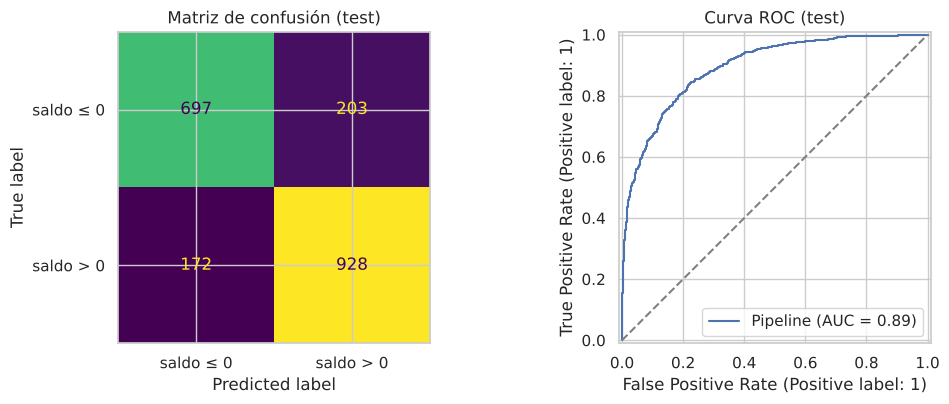

AUC de CV del Lasso sin país: 0.8911 | con país: 0.8911


In [ ]:
modelo_final = armar_pipeline(PRED_SUP, regresion_logistica("l1", C=C_1SE)).fit(X_train, y_train)
base_sin_pen = armar_pipeline(PRED_SUP, regresion_logistica("ninguna")).fit(X_train, y_train)
X_test = empresas.loc[test_idx, PRED_SUP]

def evaluar(modelo, X, y_real):
    p = modelo.predict_proba(X)[:, 1]; yh = (p >= 0.5).astype(int)
    return {"AUC": roc_auc_score(y_real, p), "accuracy": accuracy_score(y_real, yh),
            "balanced accuracy": balanced_accuracy_score(y_real, yh), "F1": f1_score(y_real, yh)}

res = pd.DataFrame({f"Lasso (C={C_1SE:.3f}, 1 SE)": evaluar(modelo_final, X_test, y_test),
                    "Logística sin penalizar": evaluar(base_sin_pen, X_test, y_test)}).T
res.loc["Regla trivial (siempre 'positivo')"] = [0.5, max(y_test.mean(), 1 - y_test.mean()), 0.5, np.nan]
print(res.round(3))

n_nn = int((modelo_final.named_steps["clf"].coef_[0] != 0).sum())
print(f"\nLasso conserva {n_nn} de {len(nombres)} coeficientes.")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
ConfusionMatrixDisplay.from_estimator(modelo_final, X_test, y_test, ax=axes[0], display_labels=["saldo ≤ 0", "saldo > 0"], colorbar=False)
axes[0].set_title("Matriz de confusión (test)")
RocCurveDisplay.from_estimator(modelo_final, X_test, y_test, ax=axes[1]); axes[1].plot([0, 1], [0, 1], "--", color="gray")
axes[1].set_title("Curva ROC (test)")
plt.tight_layout(); plt.show()

# Chequeo comprometido en 'Decisiones clave' #2: ¿cambia algo si se incluyen las variables de país?
def lasso_cv(predictores):
    gs = GridSearchCV(armar_pipeline(predictores, regresion_logistica("l1")), {"clf__C": GRILLA_C[::2]},
                      cv=cv, scoring="roc_auc", n_jobs=-1).fit(empresas.loc[train_idx, predictores], y_train)
    return gs.best_score_
print(f"AUC de CV del Lasso sin país: {lasso_cv(PRED_SUP):.4f} | con país: {lasso_cv(PRED_SUP_CON_PAIS):.4f}")

**Lectura.** El AUC en test es ≈ 0,89 y coincide con el de CV (no hay sobreajuste ni suerte en el split). La accuracy ≈ 0,81 está ≈ 26 puntos por encima del piso trivial de 0,55; la balanced accuracy ≈ 0,81 confirma que el modelo acierta parejo en ambas clases. El Lasso con penalización fuerte **empata** con la logística sin penalizar en test: se llegó a un modelo mucho más chico sin perder desempeño. Incluir las variables de país no cambia el AUC de CV (0,8911 con y sin ellas), lo que justifica haberlas dejado fuera.

## B.7 Interpretación: ¿qué variables importan?

In [ ]:
coefs = pd.Series(modelo_final.named_steps["clf"].coef_[0],
                  index=[n.replace("num__", "").replace("cat__", "") for n in nombres])
vivos = coefs[coefs != 0].sort_values(key=np.abs, ascending=False)
tabla_coef = pd.DataFrame({"coeficiente (por 1 DE)": vivos, "odds ratio": np.exp(vivos)}).round(3)
print("Variables que sobreviven al Lasso:"); print(tabla_coef.to_string())
print("\nAnuladas:", ", ".join(coefs[coefs == 0].index))

Variables que sobreviven al Lasso:
                          coeficiente (por 1 DE)  odds ratio
task_automation_rate                      -3.903       0.020
ai_adoption_rate                           3.644      38.259
ai_projects_active                         0.313       1.367
ai_budget_percentage                       0.268       1.307
ai_training_hours                          0.263       1.301
remote_work_percentage                     0.067       1.069
num_ai_tools_used                          0.059       1.060
ai_failure_rate                           -0.010       0.990
ai_risk_management_score                   0.005       1.005
years_using_ai                             0.000       1.000

Anuladas: num_employees, annual_revenue_usd_millions, company_age, antiguedad_ia_relativa, regulatory_compliance_score, industry_Consulting, industry_Education, industry_Finance, industry_Healthcare, industry_Logistics, industry_Manufacturing, industry_Retail, industry_Technology, region_Asia

**Lectura.** Dos variables concentran casi todo el peso y con **signos opuestos y magnitudes parecidas**: `ai_adoption_rate` (positivo) y `task_automation_rate` (negativo). Las demás sobrevivientes tienen coeficientes entre 12 y varios cientos de veces menores. Se anulan por completo la industria, la región, la etapa de adopción, la política de IA del país, el comité de ética, el tamaño y la edad de la empresa.

Esto **no** debe leerse como "la adopción aumenta el empleo y la automatización lo destruye de forma independiente". Dos razones, que se verifican a continuación:

1. `ai_adoption_rate` y `task_automation_rate` están correlacionadas con r ≈ 0,91. Con predictores casi colineales, los coeficientes individuales son inestables y el modelo usa su **diferencia** como señal.
2. Si cada una se mira por separado, casi no predice. Juntas, predicen mucho: es un **efecto supresor**.

In [ ]:
def auc_test(cols):
    p = armar_pipeline(cols, regresion_logistica("ninguna")).fit(empresas.loc[train_idx, cols], y_train)
    return roc_auc_score(y_test, p.predict_proba(empresas.loc[test_idx, cols])[:, 1])

print(f"correlación adopción–automatización: {empresas['ai_adoption_rate'].corr(empresas['task_automation_rate']):.2f}\n")
supresor = pd.Series({
    "solo ai_adoption_rate": auc_test(["ai_adoption_rate"]),
    "solo task_automation_rate": auc_test(["task_automation_rate"]),
    "ambas juntas": auc_test(["ai_adoption_rate", "task_automation_rate"]),
    "modelo completo (Lasso)": roc_auc_score(y_test, modelo_final.predict_proba(X_test)[:, 1])})
print("AUC en test:"); print(supresor.round(3).to_string())

# Ablación: ¿qué pasa si se saca task_automation_rate? (re-tuneando C)
sin_auto = [c for c in PRED_SUP if c != "task_automation_rate"]
print(f"\nLasso sin task_automation_rate — AUC de CV: {lasso_cv(sin_auto):.4f} (vs. {lasso_cv(PRED_SUP):.4f} con ella)")

correlación adopción–automatización: 0.91

AUC en test:
solo ai_adoption_rate        0.695
solo task_automation_rate    0.541
ambas juntas                 0.888
modelo completo (Lasso)      0.894



Lasso sin task_automation_rate — AUC de CV: 0.7888 (vs. 0.8911 con ella)


**Lectura.** Una por una, `ai_adoption_rate` alcanza un AUC ≈ 0,70 y `task_automation_rate` queda prácticamente en el azar (≈ 0,54). **Juntas llegan a ≈ 0,89**, casi el nivel del modelo completo de 34 columnas (0,894): todas las demás variables juntas aportan casi nada extra. Si se saca `task_automation_rate`, el AUC cae a ≈ 0,79.

**Interpretación en términos del problema.** La información relevante para el signo del saldo neto no es *cuánta* IA adoptó la empresa ni *cuánto* automatiza por separado, sino **cuánta adopción hay en relación con cuánta automatización de tareas**. Una empresa que adopta mucho pero automatiza proporcionalmente menos tiende a un saldo neto positivo; una que automatiza más de lo que su adopción "explica", a uno negativo. Esto es consistente con lo que el P1 había observado a nivel industria (la automatización sola no determina el saldo neto), aunque acá se lee a nivel empresa.

**Precauciones.** (i) Es una asociación predictiva, no un efecto causal. (ii) El dataset es sintético: una señal tan limpia (dos variables que lo explican casi todo) puede reflejar la regla que generó los datos más que un fenómeno del mercado laboral real. (iii) Que el Lasso anule una variable significa "no aporta información *adicional* dado el resto", no "no tiene relación con el resultado".

---
# Parte C — Integración: qué le agrega el no supervisado al supervisado

La Parte A describió el *paisaje* (un gradiente continuo de intensidad de adopción, `PC1`); la Parte B encontró la *señal predictiva* (el contraste adopción − automatización). La pregunta de integración es: **¿son la misma cosa o dos cosas distintas?** Si el clasificador solo estuviera leyendo el gradiente de PC1, el no supervisado explicaría todo el modelo; si lee algo adicional, hay que ver qué.

Se verifican tres cosas, **usando únicamente el test para las métricas**:
1. ¿Cuánto predice PC1 por sí sola?
2. ¿Sigue discriminando el modelo **dentro de un mismo nivel** del gradiente (terciles de PC1)? Si lo hiciera solo gracias a PC1, dentro de un tercil su AUC se desplomaría.
3. ¿El contraste adopción − automatización se parece al eje PC1?

AUC en test:
PC1 sola (global)                              0.702
Modelo Lasso (global)                          0.894
Modelo Lasso dentro del tercil bajo de PC1     0.872
Modelo Lasso dentro del tercil medio de PC1    0.870
Modelo Lasso dentro del tercil alto de PC1     0.889

corr(contraste, PC1) = 0.18
corr con saldo_neto_positivo → PC1: 0.31 | contraste: 0.62


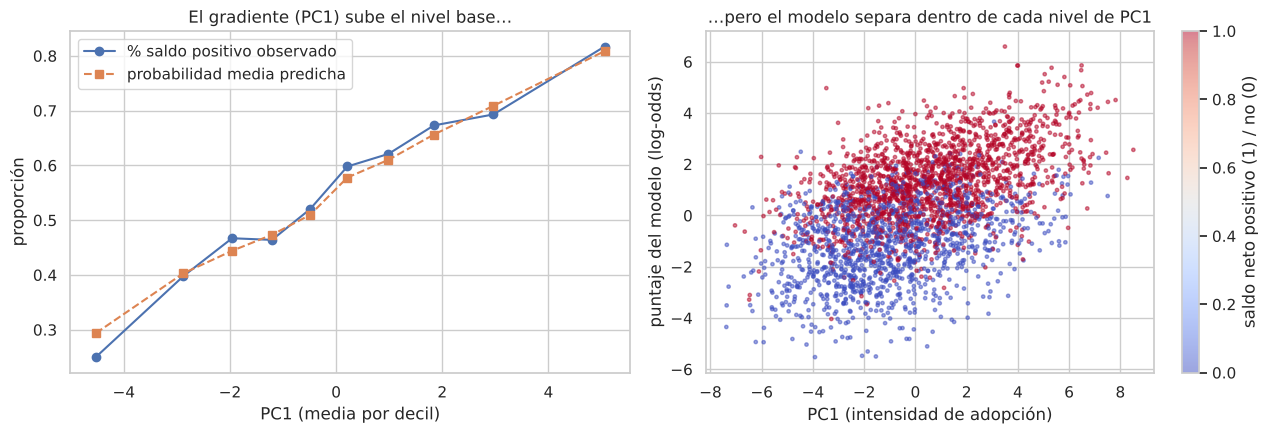

In [ ]:
empresas["p_saldo_positivo"] = modelo_final.predict_proba(empresas[PRED_SUP])[:, 1]
empresas["score_logit"] = modelo_final.decision_function(empresas[PRED_SUP])
t = empresas.loc[test_idx]

# 1) y 2) AUC de PC1 sola y del modelo, global y dentro de cada tercil del gradiente
integ = {"PC1 sola (global)": roc_auc_score(t["saldo_neto_positivo"], t["PC1"]),
         "Modelo Lasso (global)": roc_auc_score(t["saldo_neto_positivo"], t["p_saldo_positivo"])}
for q in ["bajo", "medio", "alto"]:
    m = t["tercil_PC1"] == q
    integ[f"Modelo Lasso dentro del tercil {q} de PC1"] = roc_auc_score(t.loc[m, "saldo_neto_positivo"], t.loc[m, "p_saldo_positivo"])
print("AUC en test:"); print(pd.Series(integ).round(3).to_string())

# 3) contraste adopción − automatización (estandarizado) vs PC1 y vs el resultado
za = stats.zscore(empresas["ai_adoption_rate"]); zt = stats.zscore(empresas["task_automation_rate"])
contraste = za - zt
print(f"\ncorr(contraste, PC1) = {np.corrcoef(contraste, empresas['PC1'])[0, 1]:.2f}")
print(f"corr con saldo_neto_positivo → PC1: {np.corrcoef(empresas['PC1'], empresas['saldo_neto_positivo'])[0, 1]:.2f} | "
      f"contraste: {np.corrcoef(contraste, empresas['saldo_neto_positivo'])[0, 1]:.2f}")

# Figura: (a) el gradiente fija el nivel; (b) la señal del modelo es perpendicular al gradiente
empresas["decil_PC1"] = pd.qcut(empresas["PC1"], 10, labels=False)
curva = empresas.groupby("decil_PC1").agg(PC1=("PC1", "mean"), observado=("saldo_neto_positivo", "mean"),
                                          predicho=("p_saldo_positivo", "mean"))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(curva.PC1, curva.observado, "o-", label="% saldo positivo observado")
axes[0].plot(curva.PC1, curva.predicho, "s--", label="probabilidad media predicha")
axes[0].set(title="El gradiente (PC1) sube el nivel base…", xlabel="PC1 (media por decil)", ylabel="proporción"); axes[0].legend()
muestra = empresas.sample(3000, random_state=SEMILLA)
sc = axes[1].scatter(muestra.PC1, muestra.score_logit, c=muestra.saldo_neto_positivo, cmap="coolwarm", s=6, alpha=0.5)
axes[1].set(title="…pero el modelo separa dentro de cada nivel de PC1", xlabel="PC1 (intensidad de adopción)",
            ylabel="puntaje del modelo (log-odds)")
plt.colorbar(sc, ax=axes[1], label="saldo neto positivo (1) / no (0)")
plt.tight_layout(); plt.show()

**Lectura de la integración.**

- **PC1 sola es un predictor moderado** (AUC ≈ 0,70): el gradiente sube el *nivel base* de saldo positivo (de ≈ 38 % en el tercil bajo a ≈ 72 % en el alto), como se ve en el panel izquierdo.
- **El modelo discrimina igual de bien dentro de cada nivel del gradiente** (AUC ≈ 0,87–0,89 en los tres terciles). Por lo tanto lo que predice **no es el nivel de adopción** (eso ya lo captura PC1 y rinde poco), sino algo que varía *a igual nivel de adopción*. En el panel derecho: a un mismo valor de PC1, los puntos rojos (saldo positivo) y azules (no positivo) se separan en vertical.
- **Esa "otra cosa" es el contraste adopción − automatización**, que casi no se parece a PC1 (r ≈ 0,18) pero correlaciona con el resultado el doble que PC1 (≈ 0,62 vs ≈ 0,31). PCA no lo ve porque ordena por **varianza**, y el contraste es una dirección de *poca* varianza (adopción y automatización suben juntas); el clasificador lo ve porque ordena por **relación con el target**.

La lección metodológica: el no supervisado y el supervisado no compiten, **se complementan**. El primero garantiza que no nos perdimos tipos de empresa y que el gradiente de adopción está bien medido; el segundo muestra que la señal predictiva no está en el eje de mayor varianza. Quien se hubiera quedado con el no supervisado habría concluido "más adopción, más empleo neto" (modesto, r ≈ 0,37); quien se hubiera quedado con el supervisado sin el contexto habría visto dos coeficientes grandes y opuestos y quizás los habría interpretado como efectos independientes.

## 5. Vuelta a las preguntas del P1

**H2 — ¿se puede predecir el saldo neto de empleo a partir de la adopción de IA y las características de la empresa?** Sí, en el sentido de clasificar su **signo**: AUC ≈ 0,89 y accuracy ≈ 0,81 en datos no vistos (piso trivial: 0,55), con un modelo lineal simple. Lo que predice es la **relación entre adopción y automatización de tareas**, no la adopción a secas ni las características estructurales (industria, tamaño, región y gobernanza no aportan información adicional). La intuición del P1 —que la automatización por sí sola no determina el saldo neto— se confirma: tomada sola, `task_automation_rate` no predice mejor que el azar.

**Qué quedó sin responder / límites.**
- **La H1 del P1 (crecimiento de ingresos vs. inversión en IA) no se aborda en esta notebook.**
- **Mecanismo:** el P1 sospechaba que el *tipo* de tarea automatizada (`ai_use_case`) importaba más que el volumen. En el P2 se vio que `ai_use_case` depende de la industria y no aporta información propia; acá la industria tampoco aporta, así que esa parte de la H2 no se pudo sostener con estos datos.
- **Causalidad:** todo es asociativo y transversal.
- **Dataset sintético:** la señal tan concentrada en dos variables puede ser un rasgo del generador y no del mundo real; no se puede extrapolar a empleo real sin validación externa.
- **Ruido del target:** el P2 estimó una fiabilidad de 0,33 para `saldo_neto_empleo`. El AUC observado es alto pese a eso; no se intentó derivar un "techo teórico" de desempeño por atenuación porque esa aproximación no resultó consistente con el AUC observado. Queda como pregunta abierta cuánto del saldo es señal estable y cuánto ruido trimestral (se podría contrastar con un split-half por trimestres).
- **Una sola partición train/test y un solo dataset:** la CV da confianza interna (desvío entre folds ≈ 0,002), no validación externa.

## 6. Conclusiones finales

1. **La adopción de IA en este dataset es un gradiente continuo, no una tipología.** Ningún método encontró grupos de empresas (silhouette débil y casi igual al de una nube gaussiana, PC1 unimodal, DBSCAN con un único grupo). Quien quiera "segmentar empresas por perfil de adopción" estaría cortando un continuo.
2. **Más adopción sube a la vez la creación y el desplazamiento de empleo.** El saldo neto es la resta de dos magnitudes grandes y correlacionadas, y por eso es moderadamente sensible al nivel de adopción (r ≈ 0,37).
3. **El signo del saldo neto es predecible (AUC ≈ 0,89) y la señal está en la composición, no en el nivel:** adopción alta *relativa* a automatización de tareas ↔ saldo positivo; el contraste es una dirección que el PCA no destaca por su baja varianza.
4. **La regresión penalizada no mejora la predicción respecto de la logística plana, pero sí la lectura:** el Lasso (con regla de 1 error estándar) pasa de 34 coeficientes a 10 sin perder AUC, y el camino de regularización deja a la vista cuáles dos variables llevan la señal. Random Forest rinde menos: la relación es lineal.
5. **Cuidado con la interpretación de los coeficientes:** los dos coeficientes grandes y opuestos son un efecto supresor entre variables casi colineales (r ≈ 0,91), no efectos independientes.

**Qué haríamos distinto si volviéramos a empezar.**
- Definir desde el P2 el target (y su fiabilidad) y verificar la fiabilidad con una partición por trimestres impares/pares antes de modelar.
- Aprovechar el panel trimestral con validación agrupada por `company_id` (evitaría fuga y permitiría ver dinámica, no solo foto).
- Incorporar el contraste adopción − automatización como variable explícita e incluir una validación con un dataset real (o con otro generador) para saber qué parte de la señal es del mundo y qué parte del simulador.
- Abordar también la H1, que quedó fuera del alcance de este práctico.

---
### Referencias
- Breiman, Friedman, Olshen & Stone (1984). *Classification and Regression Trees* (regla de 1 error estándar).
- Ester, Kriegel, Sander & Xu (1996). A density-based algorithm for discovering clusters (DBSCAN). *KDD-96*.
- Hastie, Tibshirani & Friedman (2009). *The Elements of Statistical Learning*, 2.ª ed. (cap. 3 y 7).
- Jolliffe (2002). *Principal Component Analysis*, 2.ª ed.
- Kaiser (1960). The application of electronic computers to factor analysis. *Educational and Psychological Measurement*.
- Kaufman & Rousseeuw (1990). *Finding Groups in Data*.
- Rousseeuw (1987). Silhouettes: a graphical aid to the interpretation and validation of cluster analysis. *J. Comput. Appl. Math.*
- Tibshirani (1996). Regression shrinkage and selection via the lasso. *JRSS B*.
- Zou & Hastie (2005). Regularization and variable selection via the elastic net. *JRSS B*.